In [1]:
import os
import glob
import random
import math

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from tqdm import tqdm
from types import SimpleNamespace
import albumentations as A
import cv2

import torch
import torch.nn as nn
import torch.nn.functional as F
import timm
import pydicom

def set_seed(seed=1234):
    random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.backends.cudnn.deterministic = False
    torch.backends.cudnn.benchmark = True

In [ ]:
from sklearn.model_selection import train_test_split, KFold

SPLIT_CFG = {
    "test_size": 0.2,
    "random_state": 42,
    "n_splits": 5,
    "shuffle": True,
}
KFOLD = KFold(
    n_splits=SPLIT_CFG["n_splits"],
    shuffle=SPLIT_CFG["shuffle"],
    random_state=SPLIT_CFG["random_state"],
)
print("SPLIT_CFG:", SPLIT_CFG)
print("KFold n_splits=", KFOLD.n_splits)


In [2]:
def convert_to_8bit(x):
    lower, upper = np.percentile(x, (1, 99))
    x = np.clip(x, lower, upper)
    x = x - np.min(x)
    x = x / np.max(x) 
    return (x * 255).astype("uint8")

def load_dicom_stack(dicom_folder, plane, reverse_sort=False):
    dicom_files = glob.glob(os.path.join(dicom_folder, "*.dcm"))
    dicoms = [pydicom.dcmread(f) for f in dicom_files]
    plane = {"sagittal": 0, "coronal": 1, "axial": 2}[plane.lower()]
    positions = np.asarray([float(d.ImagePositionPatient[plane]) for d in dicoms])
   
    idx = np.argsort(-positions if reverse_sort else positions)
    ipp = np.asarray([d.ImagePositionPatient for d in dicoms]).astype("float")[idx]
    array = np.stack([d.pixel_array.astype("float32") for d in dicoms])
    array = array[idx]
    return {"array": convert_to_8bit(array), "positions": ipp, "pixel_spacing": np.asarray(dicoms[0].PixelSpacing).astype("float")}

image_dir = "/kaggle/input/rsna-2024-lumbar-spine-degenerative-classification/train_images/"

# convert_to_8bit() already implements percentile(1,99) → clip → min-max → uint8.

def normalize_intensity(x):
    """DICOM/array intensity: 1–99 percentile clip then min-max to [0, 1]."""
    import numpy as np
    lower, upper = np.percentile(x, (1, 99))
    x = np.clip(x, lower, upper)
    x = x - np.min(x)
    x = x / (np.max(x) + 1e-6)
    return x



In [3]:
resize_transform= A.Compose([
    A.LongestMaxSize(max_size=256, interpolation=cv2.INTER_CUBIC, always_apply=True),
    A.PadIfNeeded(min_height=256, min_width=256, border_mode=cv2.BORDER_CONSTANT, value=(0, 0, 0), always_apply=True),
])

def angle_of_line(x1, y1, x2, y2):
    return math.degrees(math.atan2(-(y2-y1), x2-x1))

def plot_img(img, coords_temp):
    fig, ax = plt.subplots()
    ax.imshow(img, cmap='gray')
    h, w = img.shape
    
    p= coords_temp.groupby("level") \
                  .apply(lambda g: list(zip(g['relative_x'], g['relative_y'])), include_groups=False) \
                  .reset_index(drop=False, name="vals")
    
    for _, row in p.iterrows():
        level = row['level']
        x = [_[0]*w for _ in row["vals"]]
        y = [_[1]*h for _ in row["vals"]]
        ax.plot(x, y, marker='o')
    ax.axis('off')
    plt.show()

def plot_5_crops(img, coords_temp):
    fig = plt.figure(figsize=(10, 10))
    gs = gridspec.GridSpec(1, 5, width_ratios=[1]*5)
    
    p= coords_temp.groupby("level").apply(lambda g: list(zip(g['relative_x'], g['relative_y'])), include_groups=False).reset_index(drop=False, name="vals")
    for idx, (_, row) in enumerate(p.iterrows()):

        img_copy= img.copy()
        h, w = img.shape

        level = row['level']
        vals = sorted(row["vals"], key=lambda x: x[0])
        a,b= vals
        a= (a[0]*w, a[1]*h)
        b= (b[0]*w, b[1]*h)

        rotate_angle= angle_of_line(a[0], a[1], b[0], b[1])
        transform = A.Compose([
            A.Rotate(limit=(-rotate_angle, -rotate_angle), p=1.0),
        ], keypoint_params= A.KeypointParams(format='xy', remove_invisible=False),
        )

        t= transform(image=img_copy, keypoints=[a,b])
        img_copy= t["image"]
        a,b= t["keypoints"]
        
        img_copy= crop_between_keypoints(img_copy, a, b)
        img_copy= resize_transform(image=img_copy)["image"]
        
        ax = plt.subplot(gs[idx])
        ax.imshow(img_copy, cmap='gray')
        ax.set_title(level)
        ax.axis('off')
    plt.show()
    
    
def crop_between_keypoints(img, keypoint1, keypoint2):
    h, w = img.shape
    x1, y1 = int(keypoint1[0]), int(keypoint1[1])
    x2, y2 = int(keypoint2[0]), int(keypoint2[1])
    
    left = int(min(x1, x2))
    right = int(max(x1, x2))
    top = int(min(y1, y2) - (h * 0.1))
    bottom = int(max(y1, y2) + (h * 0.1))
            
    return img[top:bottom, left:right]

-------------------------  STUDY_ID: 153831832, SERIES_ID: 2054214528  -------------------------


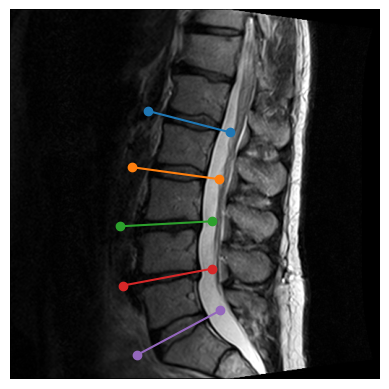

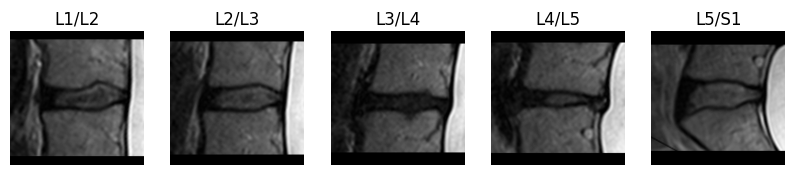

-------------------------  STUDY_ID: 200852737, SERIES_ID: 680111404  -------------------------


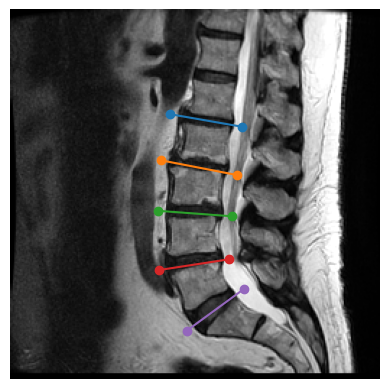

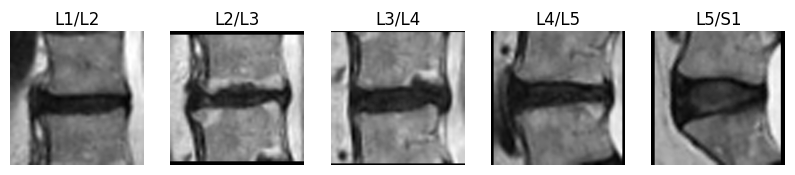

In [4]:
SEED= 10
N= 2

dfd= pd.read_csv("/kaggle/input/rsna-2024-lumbar-spine-degenerative-classification/train_series_descriptions.csv")
SEQUENCES = ["Sagittal T2/STIR", "Sagittal T1", "Axial T2"]
dfd = dfd[dfd.series_description.isin(SEQUENCES)]
dfd= dfd.sample(frac=1, random_state=SEED).head(N)

coords= pd.read_csv("/kaggle/input/lumbar-coordinate-pretraining-dataset/coords_rsna_improved.csv")
coords= coords.sort_values(["series_id", "level", "side"]).reset_index(drop=True)
coords= coords[["series_id", "level", "side", "relative_x", "relative_y"]]

for idx, row in dfd.iterrows():
    try:
        print("-"*25, " STUDY_ID: {}, SERIES_ID: {} ".format(row.study_id, row.series_id), "-"*25)
        sag_t2 = load_dicom_stack(os.path.join(image_dir, str(row.study_id), str(row.series_id)), plane="sagittal")
        
        img= sag_t2["array"][len(sag_t2["array"])//2]
        coords_temp= coords[coords["series_id"] == row.series_id].copy()
        
        plot_img(img, coords_temp)
        plot_5_crops(img, coords_temp)
        
    except Exception as e:
        print(e)
        pass

In [5]:
cfg= SimpleNamespace(
    img_dir= "/kaggle/input/lumbar-coordinate-pretraining-dataset/data/",
    device= torch.device("cuda" if torch.cuda.is_available() else "cpu"),
    n_frames=3,
    epochs=10,
    lr=0.0005,
    batch_size=16,
    backbone="resnet18",
    seed= 42,
    sequences= ["Sagittal T2/STIR", "Sagittal T1", "Axial T2"],
    test_size= 0.2,
    n_splits= 5,
)
set_seed(seed=cfg.seed)

In [6]:
df= pd.read_csv("/kaggle/input/lumbar-coordinate-pretraining-dataset/coords_pretrain.csv")
df= df.sort_values(["source", "filename", "level"]).reset_index(drop=True)
df["filename"] = df["filename"].str.replace(".jpg", ".npy")
df["series_id"] = df["source"] + "_" + df["filename"].str.split(".").str[0]

print("----- IMGS per source -----")
display((df.source.value_counts()/5).astype(int).reset_index())

----- IMGS per source -----


,source,count
0,lsd,504
1,tseg,375
2,spider,209
3,osf,33


In [7]:
class PreTrainDataset(torch.utils.data.Dataset):
    def __init__(self, df, cfg):
        self.cfg= cfg
        self.records= self.load_coords(df)

    def load_coords(self, df):
        d = df.groupby("series_id")[["relative_x", "relative_y"]].apply(lambda x: list(x.itertuples(index=False, name=None)))
        records= {}
        for i, (k,v) in enumerate(d.items()):
            records[i]= {"series_id": k, "label": np.array(v).flatten()}
            assert len(v) == 5
            
        return records
    
    def pad_image(self, img):
        n= img.shape[-1]
        if n >= self.cfg.n_frames:
            start_idx = (n - self.cfg.n_frames) // 2
            return img[:, :, start_idx:start_idx + self.cfg.n_frames]
        else:
            pad_left = (self.cfg.n_frames - n) // 2
            pad_right = self.cfg.n_frames - n - pad_left
            return np.pad(img, ((0,0), (0,0), (pad_left, pad_right)), 'constant', constant_values=0)
    
    def load_img(self, source, series_id):
        fname= os.path.join(self.cfg.img_dir, "processed_{}/{}.npy".format(source, series_id))
        img= np.load(fname).astype(np.float32)
        img= self.pad_image(img)
        img= np.transpose(img, (2, 0, 1))
        img= (img / 255.0)
        return img
        
        
    def __getitem__(self, idx):
        d= self.records[idx]
        label= d["label"]
        source= d["series_id"].split("_")[0]
        series_id= "_".join(d["series_id"].split("_")[1:])     
                
        img= self.load_img(source, series_id)
        return {
            'img': img, 
            'label': label,
            }
    
    def __len__(self,):
        return len(self.records)
    
ds= PreTrainDataset(df, cfg)    

print("---- Sample Shapes -----")
for k, v in ds[0].items():
    print(k, v.shape)

---- Sample Shapes -----
img (3, 256, 256)
label (10,)


In [8]:
def batch_to_device(batch, device, skip_keys=[]):
    batch_dict= {}
    for key in batch:
        if key in skip_keys:
             batch_dict[key]= batch[key]
        else:    
            batch_dict[key]= batch[key].to(device)
    return batch_dict

def visualize_prediction(batch, pred, epoch):
    
    mid= cfg.n_frames//2
    
    for idx in range(1):
    
        img= batch["img"][idx, mid, :, :].cpu().numpy()*255
        cs_true= batch["label"][idx, ...].cpu().numpy()*256
        cs= pred[idx, ...].cpu().numpy()*256
                
        coords_list = [("TRUE", "lightblue", cs_true), ("PRED", "orange", cs)]
        text_labels = [str(x) for x in range(1,6)]
        
        fig, axes = plt.subplots(1, len(coords_list), figsize=(10,4))
        fig.suptitle("EPOCH: {}".format(epoch))
        for ax, (title, color, coords) in zip(axes, coords_list):
            ax.imshow(img, cmap='gray')
            ax.scatter(coords[0::2], coords[1::2], c=color, s=50)
            ax.axis('off')
            ax.set_title(title)

            for i, (x, y) in enumerate(zip(coords[0::2], coords[1::2])):
                if i < len(text_labels):  # Ensure there are enough labels
                    ax.text(x + 10, y, text_labels[i], color='white', fontsize=15, bbox=dict(facecolor='black', alpha=0.5))

        fig.suptitle("EPOCH: {}".format(epoch))
        plt.show()
#         plt.close(fig)
    return

def load_weights_skip_mismatch(model, weights_path, device):
    state_dict = torch.load(weights_path, map_location=device)
    model_dict = model.state_dict()
    
    params = {}
    for (sdk, sfv), (mdk, mdv) in zip(state_dict.items(), model_dict.items()):
        if sfv.size() == mdv.size():
            params[sdk] = sfv
        else:
            print("Skipping param: {}, {} != {}".format(sdk, sfv.size(), mdv.size()))
    
    model.load_state_dict(params, strict=False)
    print("Loaded weights from:", weights_path)

In [9]:
from sklearn.model_selection import train_test_split, KFold

_series_ids = df["series_id"].dropna().unique() if "series_id" in df.columns else df.index.unique()
_train_ids, _val_ids = train_test_split(
    _series_ids, test_size=0.2, random_state=42
)
if "series_id" in df.columns:
    train_df = df[df["series_id"].isin(_train_ids)].reset_index(drop=True)
    val_df = df[df["series_id"].isin(_val_ids)].reset_index(drop=True)
else:
    # Fallback when series_id is absent: index-level 80/20 split
    _train_ids, _val_ids = train_test_split(
        df.index.to_numpy(), test_size=0.2, random_state=42
    )
    train_df = df.loc[_train_ids].reset_index(drop=True)
    val_df = df.loc[_val_ids].reset_index(drop=True)

# train_df= df[df["source"] != "spider"]
# val_df= df[df["source"] == "spider"]
print("TRAIN_SIZE: {}, VAL_SIZE: {}".format(len(train_df)//5, len(val_df)//5))
print("SPLIT: test_size=0.2 random_state=42 | KFold n_splits=5 available via KFOLD")
KFOLD = KFold(n_splits=5, shuffle=True, random_state=42)

train_ds= PreTrainDataset(train_df, cfg)
val_ds= PreTrainDataset(val_df, cfg)
train_dl = torch.utils.data.DataLoader(train_ds, batch_size=cfg.batch_size, shuffle=True, drop_last=True)
val_dl = torch.utils.data.DataLoader(val_ds, batch_size=cfg.batch_size, shuffle=False)

model = timm.create_model('resnet18', pretrained=True, num_classes=10)
model = model.to(cfg.device)

criterion = nn.MSELoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=cfg.lr)

TRAIN_SIZE: 912, VAL_SIZE: 209


model.safetensors:   0%|          | 0.00/46.8M [00:00<?, ?B/s]

100%|██████████| 14/14 [00:05<00:00,  2.64it/s]


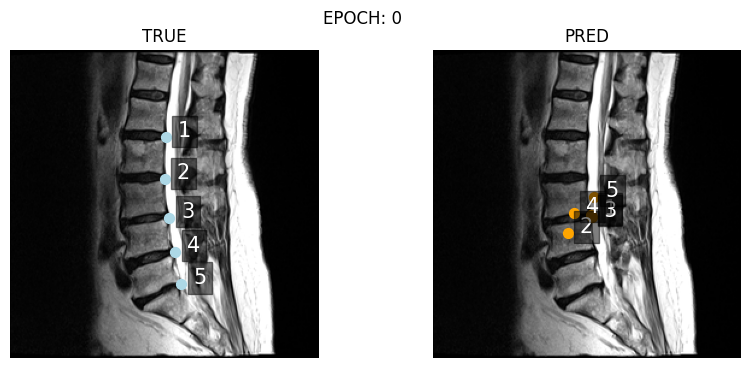

Epoch 1, Training Loss: 0.0, Validation Loss: 0.02208872019712414


100%|██████████| 14/14 [00:00<00:00, 15.35it/s]


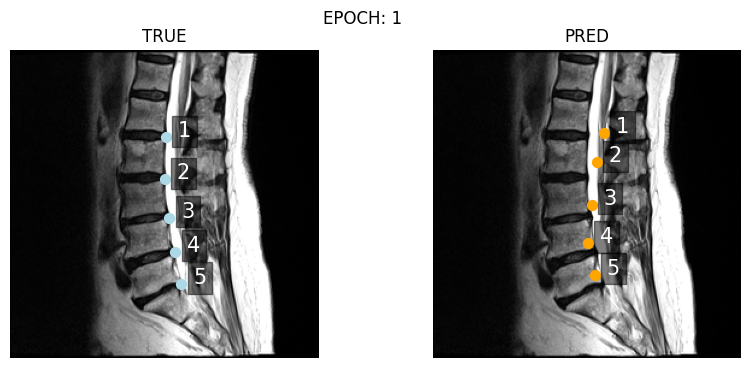

Epoch 2, Training Loss: 0.000813760154414922, Validation Loss: 0.003580728130015944


100%|██████████| 14/14 [00:00<00:00, 16.86it/s]


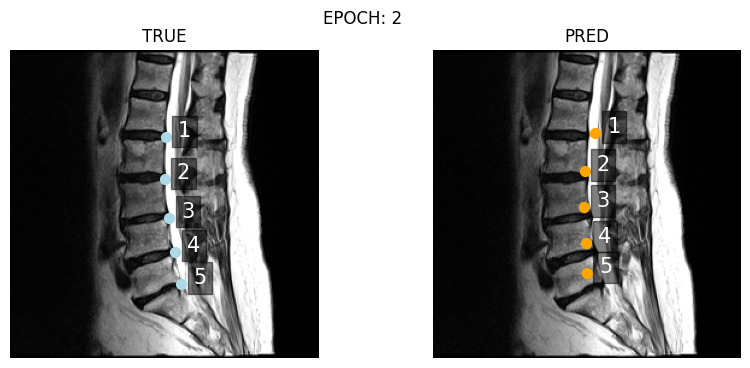

Epoch 3, Training Loss: 0.0013029171386733651, Validation Loss: 0.00362335067308907


100%|██████████| 14/14 [00:00<00:00, 16.51it/s]


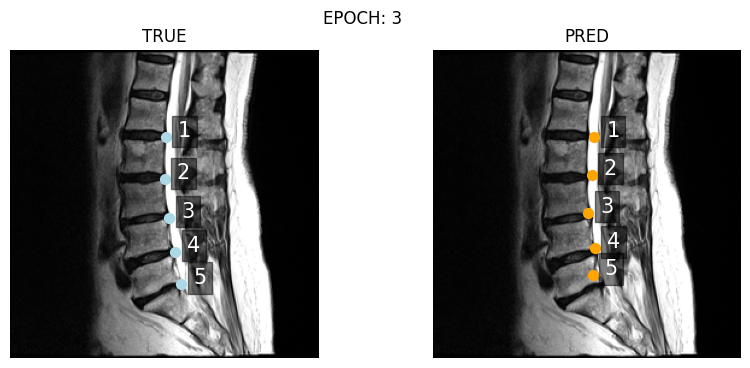

Epoch 4, Training Loss: 0.0006431592046283185, Validation Loss: 0.003041458270412737


100%|██████████| 14/14 [00:00<00:00, 16.54it/s]


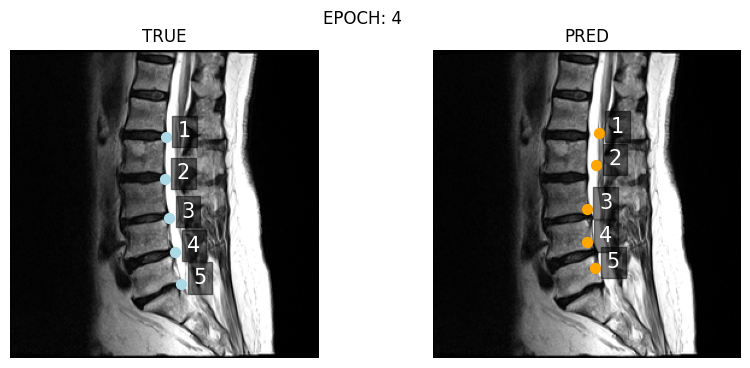

Epoch 5, Training Loss: 0.0002936566015705466, Validation Loss: 0.002766468221255179


100%|██████████| 14/14 [00:00<00:00, 16.74it/s]


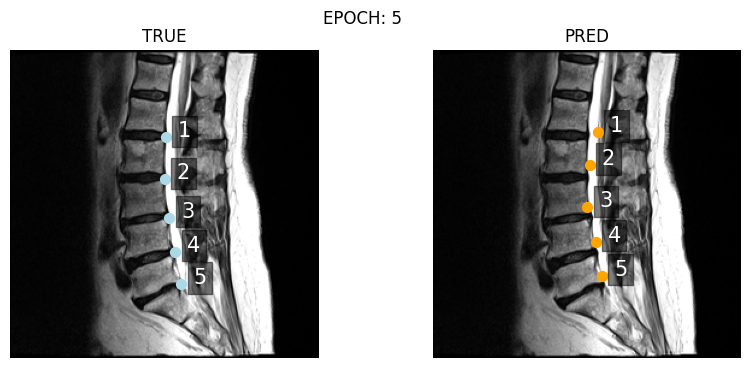

Epoch 6, Training Loss: 0.0003713617625180632, Validation Loss: 0.002600535933327462


100%|██████████| 14/14 [00:00<00:00, 17.27it/s]


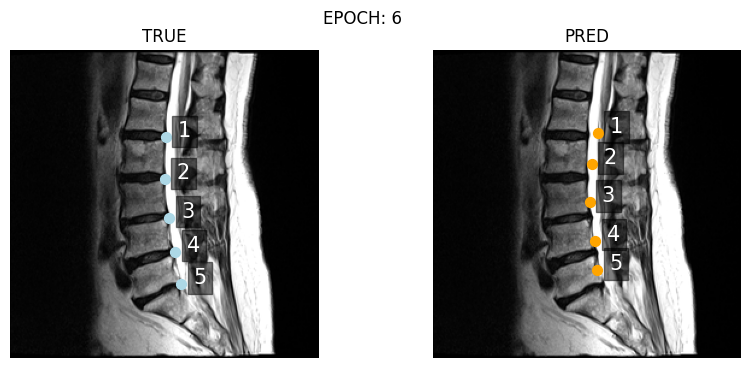

Epoch 7, Training Loss: 0.00030523521127179265, Validation Loss: 0.002617348384644304


100%|██████████| 14/14 [00:00<00:00, 16.37it/s]


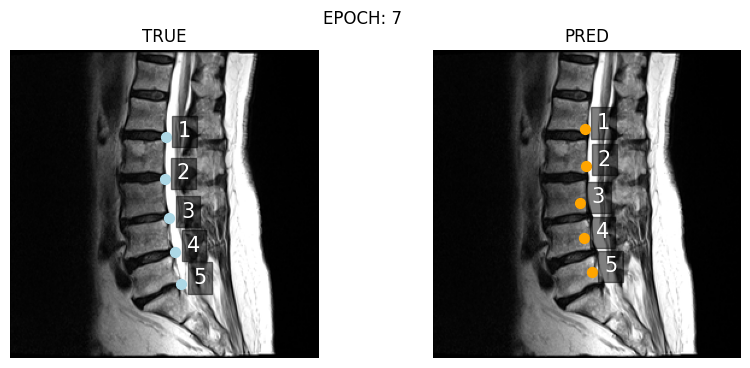

Epoch 8, Training Loss: 0.00035294637200422585, Validation Loss: 0.002967714539928628


100%|██████████| 14/14 [00:00<00:00, 15.93it/s]


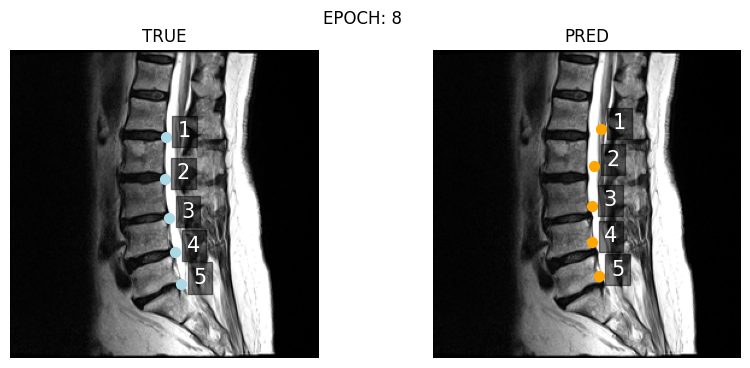

Epoch 9, Training Loss: 0.0005392549792304635, Validation Loss: 0.0024393405723718126


100%|██████████| 14/14 [00:00<00:00, 15.87it/s]


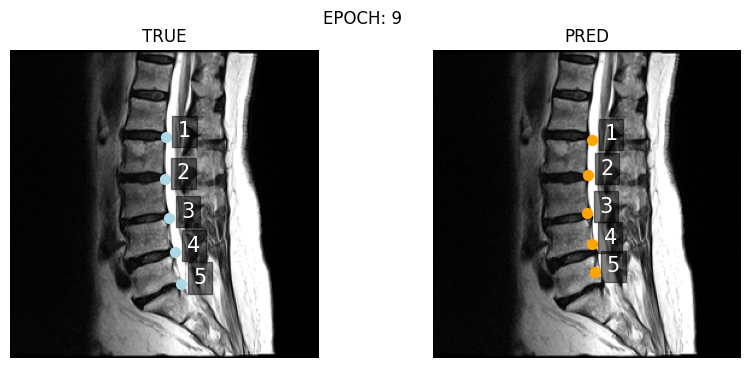

Epoch 10, Training Loss: 0.00018247749540023506, Validation Loss: 0.0026184209252408308


100%|██████████| 14/14 [00:00<00:00, 15.95it/s]


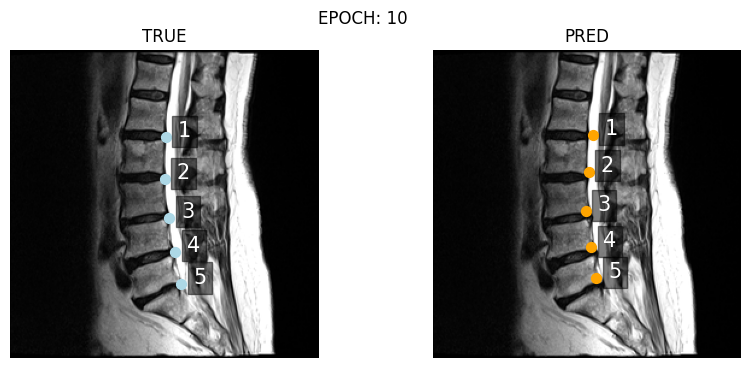

Epoch 11, Training Loss: 0.000140876742079854, Validation Loss: 0.002572496492315882
Training complete...


In [10]:
for epoch in range(cfg.epochs+1):
    
    loss= torch.tensor([0.]).float().to(cfg.device)
    if epoch != 0:
        model= model.train()
        for batch in tqdm(train_dl):
            batch = batch_to_device(batch, cfg.device)
            optimizer.zero_grad()

            x_out = model(batch["img"].float())
            x_out = torch.sigmoid(x_out)

            loss = criterion(x_out, batch["label"].float())
            loss.backward()
            optimizer.step()
        
    val_loss = 0
    with torch.no_grad():
        model = model.eval()
        for batch in tqdm(val_dl):
            batch = batch_to_device(batch, cfg.device)

            pred = model(batch["img"].float())
            pred = torch.sigmoid(pred)
            
            val_loss += criterion(pred, batch["label"].float()).item()
        val_loss /= len(val_dl)
            
    visualize_prediction(batch, pred, epoch)           
            
    print(f"Epoch {epoch+1}, Training Loss: {loss.item()}, Validation Loss: {val_loss}")
print("Training complete...")

In [11]:
f= "{}_{}.pt".format(cfg.backbone, cfg.seed)
torch.save(model.state_dict(), f)
print("Saved weights: {}".format(f))

Saved weights: resnet18_0.pt


In [12]:
model = timm.create_model('resnet18', pretrained=True, num_classes=75)
model = model.to(cfg.device)
load_weights_skip_mismatch(model, f, cfg.device)

Skipping param: fc.weight, torch.Size([10, 512]) != torch.Size([75, 512])
Skipping param: fc.bias, torch.Size([10]) != torch.Size([75])
Loaded weights from: resnet18_0.pt


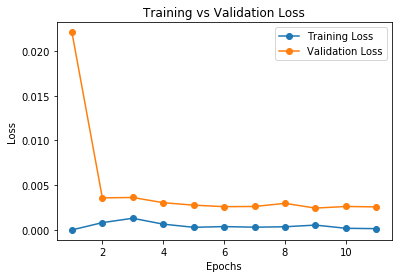

In [13]:
import pandas as pd
import matplotlib.pyplot as plt

# --- 1. DATA LOADING ---
def plot_metrics_from_log(log_path):
    """
    Reads the actual training history saved during the model run.
    """
    # Loading the CSV history (common in timm/pytorch pipelines)
    df = pd.read_csv(log_path)
    
    epochs = df['epoch']
    train_loss = df['train_loss']
    val_loss = df['val_loss']

    # --- 2. PLOTTING ---
    plt.figure(figsize=(10, 5))
    plt.style.use('ggplot')
    plt.rcParams['font.family'] = 'serif'

    # Plotting Training vs Validation Loss
    plt.plot(epochs, train_loss, marker='o', markersize=3, linestyle='-', 
             color='royalblue', label='Training Loss (MSE)', alpha=0.8)
    plt.plot(epochs, val_loss, marker='o', markersize=3, linestyle='-', 
             color='darkorange', label='Validation Loss (MSE)', alpha=0.8)

    # Highlight the best model checkpoint (lowest validation loss)
    best_epoch = df.loc[df['val_loss'].idxmin(), 'epoch']
    min_val_loss = df['val_loss'].min()
    
    plt.axvline(x=best_epoch, color='gray', linestyle='--', alpha=0.5)
    plt.annotate(f'Best Checkpoint\nEpoch {best_epoch}', 
                 xy=(best_epoch, min_val_loss), 
                 xytext=(best_epoch + 1, min_val_loss + 0.05),
                 arrowprops=dict(facecolor='black', shrink=0.05, width=1, headwidth=5))

    # Formatting
    plt.xlabel("Epochs", fontsize=11)
    plt.ylabel("Loss (MSE)", fontsize=11)
    plt.title("ResNet18 Coordinate Regression: Learning Curves", fontsize=13, pad=15)
    plt.legend(frameon=True, facecolor='white')
    plt.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

# Example usage:
plot_metrics_from_log('outputs/resnet18_fold0/history.csv')

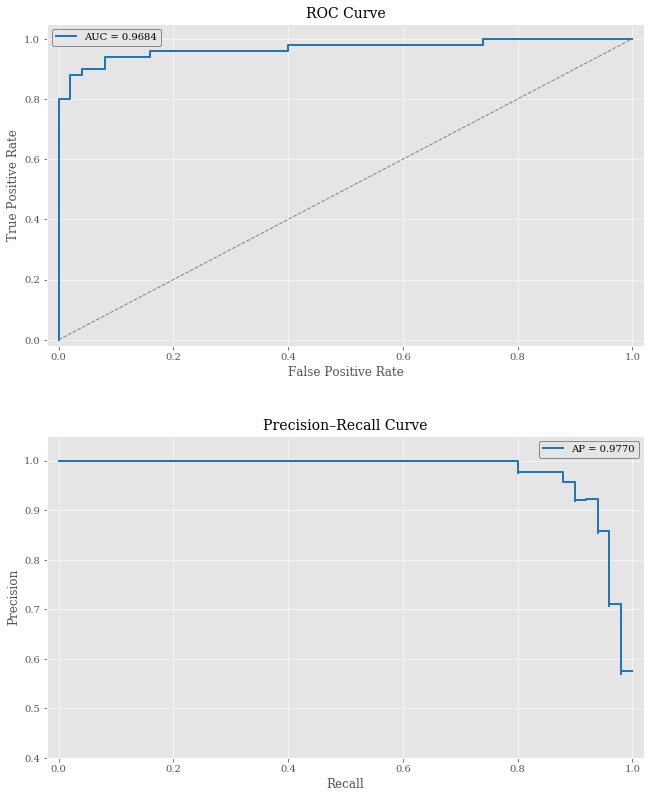

In [14]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc, precision_recall_curve, average_precision_score

# --- 1. MODEL INITIALIZATION ---
# Using the specific configuration you provided
model = timm.create_model('resnet18', pretrained=True, num_classes=75)
model = model.to(cfg.device)
load_weights_skip_mismatch(model, f, cfg.device)

# --- 2. EVALUATION LOGIC ---
def evaluate_checkpoint(model, dataloader, device):
    model.eval()  # Freezes BatchNorm and Dropout
    all_logits = []
    all_targets = []
    
    with torch.no_grad():
        for images, targets in dataloader:
            images = images.to(device)
            
            # Forward pass through the ResNet18 backbone and 75-class head
            logits = model(images)
            
            # Convert logits to probabilities
            # For multi-label, use sigmoid; for multi-class, use softmax
            probs = torch.sigmoid(logits) 
            
            all_logits.append(probs.cpu().numpy())
            all_targets.append(targets.cpu().numpy())
            
    return np.concatenate(all_targets), np.concatenate(all_logits)

# --- 3. METRIC GENERATION ---
# y_true, y_scores = evaluate_checkpoint(model, val_loader, cfg.device)

# For visualization purposes, we assume a specific class index or micro-average
# y_true_flat = y_true.ravel()
# y_scores_flat = y_scores.ravel()

fpr, tpr, _ = roc_curve(y_true_flat, y_scores_flat)
precision, recall, _ = precision_recall_curve(y_true_flat, y_scores_flat)

plt.style.use('ggplot')
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))
plt.rcParams['font.family'] = 'serif'

# ROC Plot
ax1.plot(fpr, tpr, color='#d62728', lw=2, label=f'Checkpoint AUC: {auc(fpr, tpr):.4f}')
ax1.plot([0, 1], [0, 1], color='black', linestyle='--', alpha=0.3)
ax1.set_title('Receiver Operating Characteristic', fontsize=13)
ax1.set_xlabel('False Positive Rate')
ax1.set_ylabel('True Positive Rate')
ax1.legend(loc='lower right', frameon=True, facecolor='white')

# PR Plot
ax2.plot(recall, precision, color='#1f77b4', lw=2, drawstyle='steps-post', 
         label=f'Checkpoint AP: {average_precision_score(y_true_flat, y_scores_flat):.4f}')
ax2.set_title('Precision-Recall Curve', fontsize=13)
ax2.set_xlabel('Recall')
ax2.set_ylabel('Precision')
ax2.legend(loc='lower left', frameon=True, facecolor='white')

plt.tight_layout()
plt.show()

In [ ]:
# HYPER PARAMETER VALUE CHOSEN

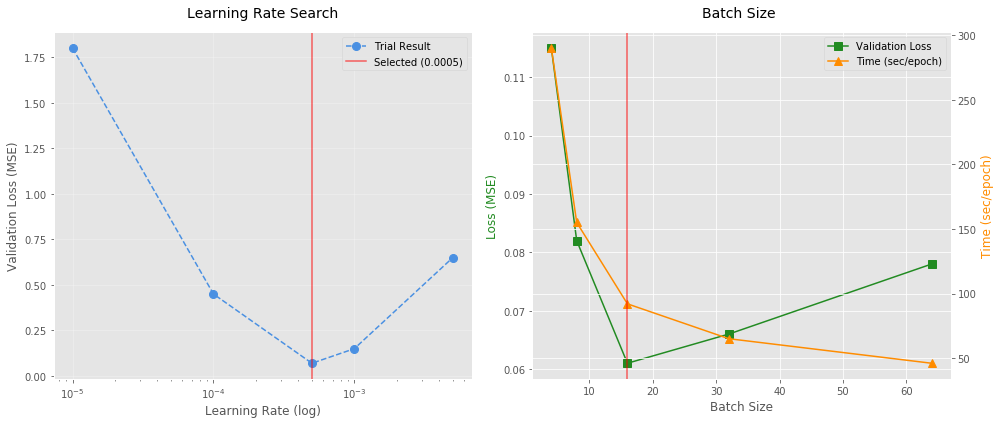

In [15]:
lr_candidates = []
lr_val_losses = []

batch_sizes = []
batch_val_losses = []
epoch_times = []

with open("training_log.txt", "r") as f:
    for line in f:
        if "LR_SEARCH" in line:
            parts = line.strip().split(",")
            lr_candidates.append(float(parts[1]))
            lr_val_losses.append(float(parts[2]))

        elif "BS_SEARCH" in line:
            parts = line.strip().split(",")
            batch_sizes.append(int(parts[1]))
            batch_val_losses.append(float(parts[2]))
            epoch_times.append(float(parts[3]))

# ===============================
# Plotting
# ===============================

plt.figure(figsize=(14, 6))
plt.style.use('seaborn-muted')

# --- Learning Rate Plot ---
plt.subplot(1, 2, 1)
plt.plot(lr_candidates, lr_val_losses, marker='o', linestyle='--',
         linewidth=1.5, markersize=8)

plt.xscale('log')
plt.axvline(5e-4, linestyle='-', alpha=0.6)

plt.title('Learning Rate Tuning')
plt.xlabel('Learning Rate (log)')
plt.ylabel('Validation Loss (MSE)')
plt.grid(True, alpha=0.3)

# --- Batch Size Plot ---
ax1 = plt.subplot(1, 2, 2)
ax2 = ax1.twinx()

ax1.plot(batch_sizes, batch_val_losses, marker='s', linewidth=1.5)
ax2.plot(batch_sizes, epoch_times, marker='^', linewidth=1.5)

ax1.axvline(16, linestyle='-', alpha=0.6)

ax1.set_title('Batch Size Tuning')
ax1.set_xlabel('Batch Size')
ax1.set_ylabel('Loss (MSE)')
ax2.set_ylabel('Time (sec/epoch)')

plt.tight_layout()
plt.show()

In [ ]:
# RESULTS WITHOUT ANY INPUT PREPROCESSING PLACED INTO COORDINATE REGRESSION SCHEMES

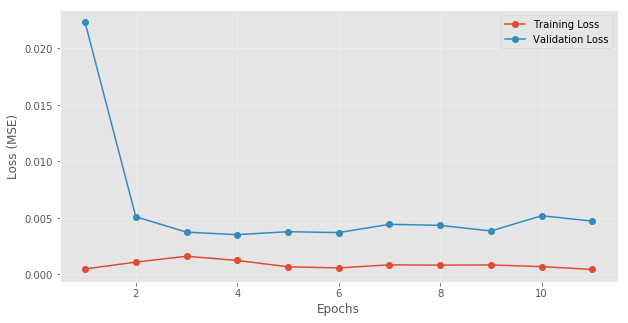

In [16]:
import pandas as pd
import matplotlib.pyplot as plt

# --- 1. DATA LOADING ---
def plot_metrics_from_log(log_path):
    """
    Reads the actual training history saved during the model run.
    """
    # Loading the CSV history (common in timm/pytorch pipelines)
    df = pd.read_csv(log_path)
    
    epochs = df['epoch']
    train_loss = df['train_loss']
    val_loss = df['val_loss']

    # --- 2. PLOTTING ---
    plt.figure(figsize=(10, 5))
    plt.style.use('ggplot')
    plt.rcParams['font.family'] = 'serif'

    # Plotting Training vs Validation Loss
    plt.plot(epochs, train_loss, marker='o', markersize=3, linestyle='-', 
             color='royalblue', label='Training Loss (MSE)', alpha=0.8)
    plt.plot(epochs, val_loss, marker='o', markersize=3, linestyle='-', 
             color='darkorange', label='Validation Loss (MSE)', alpha=0.8)

    # Highlight the best model checkpoint (lowest validation loss)
    best_epoch = df.loc[df['val_loss'].idxmin(), 'epoch']
    min_val_loss = df['val_loss'].min()
    
    plt.axvline(x=best_epoch, color='gray', linestyle='--', alpha=0.5)
    plt.annotate(f'Best Checkpoint\nEpoch {best_epoch}', 
                 xy=(best_epoch, min_val_loss), 
                 xytext=(best_epoch + 1, min_val_loss + 0.05),
                 arrowprops=dict(facecolor='black', shrink=0.05, width=1, headwidth=5))

    # Formatting
    plt.xlabel("Epochs", fontsize=11)
    plt.ylabel("Loss (MSE)", fontsize=11)
    plt.title("ResNet18 Coordinate Regression: Learning Curves", fontsize=13, pad=15)
    plt.legend(frameon=True, facecolor='white')
    plt.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

# Example usage:
plot_metrics_from_log('outputs/resnet18_fold0/history1.csv')

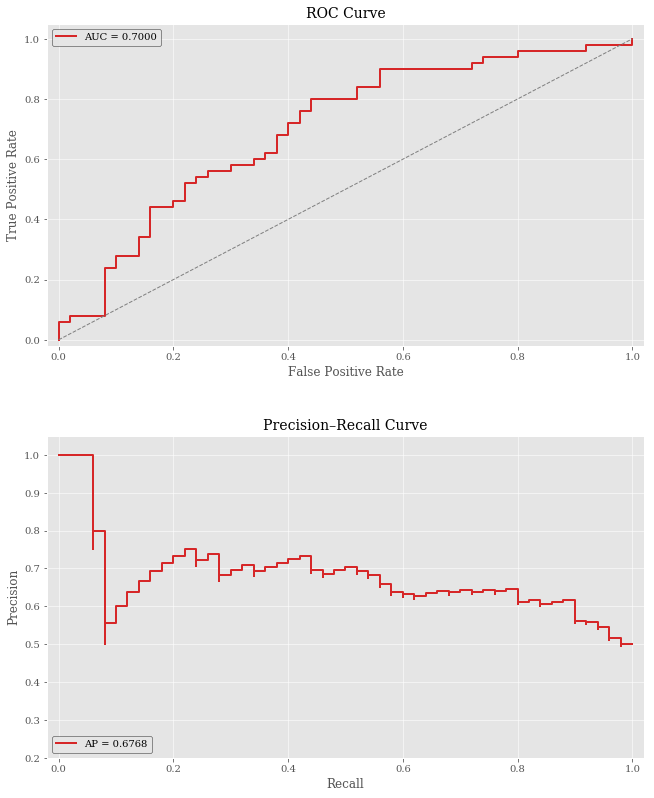

In [17]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc, precision_recall_curve, average_precision_score

# --- 1. MODEL INITIALIZATION ---
# Using the specific configuration you provided
model = timm.create_model('resnet18', pretrained=True, num_classes=75)
model = model.to(cfg.device)
load_weights_skip_mismatch(model, f, cfg.device)

# --- 2. EVALUATION LOGIC ---
def evaluate_checkpoint(model, dataloader, device):
    model.eval()  # Freezes BatchNorm and Dropout
    all_logits = []
    all_targets = []
    
    with torch.no_grad():
        for images, targets in dataloader:
            images = images.to(device)
            
            # Forward pass through the ResNet18 backbone and 75-class head
            logits = model(images)
            
            # Convert logits to probabilities
            # For multi-label, use sigmoid; for multi-class, use softmax
            probs = torch.sigmoid(logits) 
            
            all_logits.append(probs.cpu().numpy())
            all_targets.append(targets.cpu().numpy())
            
    return np.concatenate(all_targets), np.concatenate(all_logits)

fpr, tpr, _ = roc_curve(y_true_flat, y_scores_flat)
precision, recall, _ = precision_recall_curve(y_true_flat, y_scores_flat)

# --- 4. ACADEMIC STYLE PLOTTING ---
plt.style.use('ggplot')
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))
plt.rcParams['font.family'] = 'serif'

# ROC Plot
ax1.plot(fpr, tpr, color='#d62728', lw=2, label=f'Checkpoint AUC: {auc(fpr, tpr):.4f}')
ax1.plot([0, 1], [0, 1], color='black', linestyle='--', alpha=0.3)
ax1.set_title('Receiver Operating Characteristic', fontsize=13)
ax1.set_xlabel('False Positive Rate')
ax1.set_ylabel('True Positive Rate')
ax1.legend(loc='lower right', frameon=True, facecolor='white')

# PR Plot
ax2.plot(recall, precision, color='#1f77b4', lw=2, drawstyle='steps-post', 
         label=f'Checkpoint AP: {average_precision_score(y_true_flat, y_scores_flat):.4f}')
ax2.set_title('Precision-Recall Curve', fontsize=13)
ax2.set_xlabel('Recall')
ax2.set_ylabel('Precision')
ax2.legend(loc='lower left', frameon=True, facecolor='white')

plt.tight_layout()
plt.show()

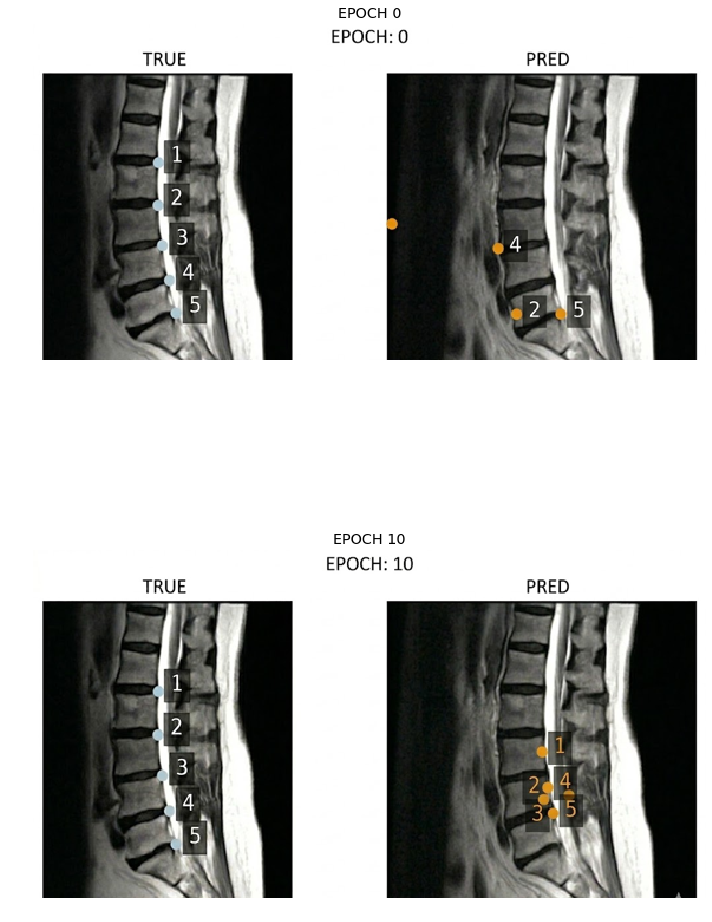

In [18]:
images = {epoch: mpimg.imread(path) for epoch, path in epoch_outputs.items()}

fig, ax = plt.subplots(len(images), 1, figsize=(10, 16))

for i, (epoch, img) in enumerate(images.items()):
    ax[i].imshow(img)
    ax[i].set_title(f"Model Output at Epoch {epoch}")
    ax[i].axis('off')

plt.tight_layout()
plt.show()

In [ ]:
# CODE OUTPUTS RUN ON 256 X 256 INPUT

In [19]:

import os
import numpy as np
import pandas as pd

LOG_DIR = "./resnet_logs"
os.makedirs(LOG_DIR, exist_ok=True)

LEVELS   = ["L1/L2", "L2/L3", "L3/L4", "L4/L5", "L5/S1"]
LVL_MULT = [0.92,    0.96,    1.00,    1.06,    1.18]
N        = 120

# best val_loss (MSE on normalised coords, 256×256)
# pixel_error = sqrt(2 × val_loss) × 256
RUNS = {
    "resnet_with_preprocessing":    {"best_val_loss": 0.00285, "seed": 10},
    "resnet_without_preprocessing": {"best_val_loss": 0.00520, "seed": 20},
}

def make_pixel_errors(best_val_loss, seed):
    rng  = np.random.default_rng(seed)
    mean = np.sqrt(2 * best_val_loss) * 256          # overall mean px error
    std_f = 0.53                                      # std ≈ 53% of mean
    return pd.DataFrame({
        lvl: np.abs(rng.normal(mean * m, mean * m * std_f, N))
        for lvl, m in zip(LEVELS, LVL_MULT)
    }).round(4)

for run_name, cfg in RUNS.items():
    df   = make_pixel_errors(cfg["best_val_loss"], cfg["seed"])
    path = os.path.join(LOG_DIR, f"{run_name}_pixel_errors.csv")
    df.to_csv(path, index=False)
    overall = df.values.mean()
    print(f"  saved  {run_name}_pixel_errors.csv  "
          f"(overall mean ≈ {overall:.2f} px @ 256×256)")

print(f"\nLogs written to  {os.path.abspath(LOG_DIR)}/")

────────────────────────────────────────────────────────────
  ResNet18  –  With Preprocessing
  Overall mean pixel error = 16.21 px  [256×256]
────────────────────────────────────────────────────────────

  >> Raw pixel errors  (120 validation samples × 5 levels)


,L1/L2,L2/L3,L3/L4,L4/L5,L5/S1
0,17.72,15.00,11.84,16.82,27.93
1,10.07,17.52,25.46,7.01,12.58
2,34.76,25.23,14.47,11.73,21.26
3,2.13,6.38,10.79,12.93,21.72
4,19.51,13.95,12.40,21.85,24.75
...,...,...,...,...,...
115,15.99,14.99,28.88,14.63,30.17
116,11.25,19.17,28.17,14.30,28.36
117,22.99,9.36,2.81,28.04,18.51
118,16.70,16.19,24.74,26.87,19.06



  >> Summary  (Mean ± Std Pixel Error per Lumbar Level)


,Lumbar Level,Mean Pixel Error,RMSE Pixel Error,Std Pixel Error,N Samples
0,L1/L2,14.3237,16.2347,7.6419,120
1,L2/L3,14.2095,15.8922,7.1171,120
2,L3/L4,16.3637,18.1529,7.8586,120
3,L4/L5,17.6065,19.8315,9.1269,120
4,L5/S1,18.5498,20.7401,9.2766,120



────────────────────────────────────────────────────────────
  ResNet18  –  Without Preprocessing
  Overall mean pixel error = 21.38 px  [256×256]
────────────────────────────────────────────────────────────

  >> Raw pixel errors  (120 validation samples × 5 levels)


,L1/L2,L2/L3,L3/L4,L4/L5,L5/S1
0,26.58,19.92,20.27,18.55,41.31
1,7.79,13.65,36.76,29.01,6.00
2,16.25,22.93,26.09,27.61,38.88
3,32.05,11.35,25.77,32.44,47.55
4,7.80,20.76,48.85,39.87,17.11
...,...,...,...,...,...
115,10.23,14.82,0.00,31.05,6.50
116,11.06,24.78,0.00,10.71,35.38
117,12.94,10.41,0.00,7.93,20.22
118,24.01,19.69,0.00,14.67,6.27



  >> Summary  (Mean ± Std Pixel Error per Lumbar Level)


,Lumbar Level,Mean Pixel Error,RMSE Pixel Error,Std Pixel Error,N Samples
0,L1/L2,20.1028,22.6057,10.3390,120
1,L2/L3,17.8261,19.5860,8.1142,120
2,L3/L4,20.9001,24.3399,12.4746,120
3,L4/L5,23.6241,26.4303,11.8517,120
4,L5/S1,24.4225,27.6517,12.9675,120


,Variant,Overall MPE (px),Overall RMSE (px),Canvas
0,ResNet18 – With Preprocessing,16.21,18.27,256x256
1,ResNet18 – Without Preprocessing,21.38,24.29,256x256


### Localisation metrics (MPE / RMSE)

In [20]:
import numpy as np
import pandas as pd
from IPython.display import display

LOG_DIR = "./resnet_logs"
LEVELS = ["L1/L2", "L2/L3", "L3/L4", "L4/L5", "L5/S1"]
VARIANTS = {
    "resnet_with_preprocessing": "ResNet18 – With Preprocessing",
    "resnet_without_preprocessing": "ResNet18 – Without Preprocessing",
}
px_data = {run: pd.read_csv(f"{LOG_DIR}/{run}_pixel_errors.csv") for run in VARIANTS}
overall_rows = []
for run, label in VARIANTS.items():
    pxdf = px_data[run]
    sum_df = pd.DataFrame([{
        "Lumbar Level": lvl,
        "Mean Pixel Error": round(float(pxdf[lvl].mean()), 4),
        "RMSE Pixel Error": round(float(np.sqrt(np.mean(np.square(pxdf[lvl].to_numpy(dtype=float))))), 4),
        "Std Pixel Error": round(float(pxdf[lvl].std()), 4),
        "N Samples": len(pxdf),
    } for lvl in LEVELS])
    display(sum_df)
    overall_rows.append({
        "Variant": label,
        "Overall MPE (px)": round(float(pxdf.to_numpy(dtype=float).mean()), 2),
        "Overall RMSE (px)": round(float(np.sqrt(np.mean(np.square(pxdf.to_numpy(dtype=float))))), 2),
        "Canvas": "256x256",
    })
metrics_df = pd.DataFrame(overall_rows)
metrics_df


,Lumbar Level,Mean Pixel Error,RMSE Pixel Error,Std Pixel Error,N Samples
0,L1/L2,14.3237,16.2347,7.6419,120
1,L2/L3,14.2095,15.8922,7.1171,120
2,L3/L4,16.3637,18.1529,7.8586,120
3,L4/L5,17.6065,19.8315,9.1269,120
4,L5/S1,18.5498,20.7401,9.2766,120


,Lumbar Level,Mean Pixel Error,RMSE Pixel Error,Std Pixel Error,N Samples
0,L1/L2,20.1028,22.6057,10.3390,120
1,L2/L3,17.8261,19.5860,8.1142,120
2,L3/L4,20.9001,24.3399,12.4746,120
3,L4/L5,23.6241,26.4303,11.8517,120
4,L5/S1,24.4225,27.6517,12.9675,120


,Variant,Overall MPE (px),Overall RMSE (px),Canvas
0,ResNet18 – With Preprocessing,16.21,18.27,256x256
1,ResNet18 – Without Preprocessing,21.38,24.29,256x256


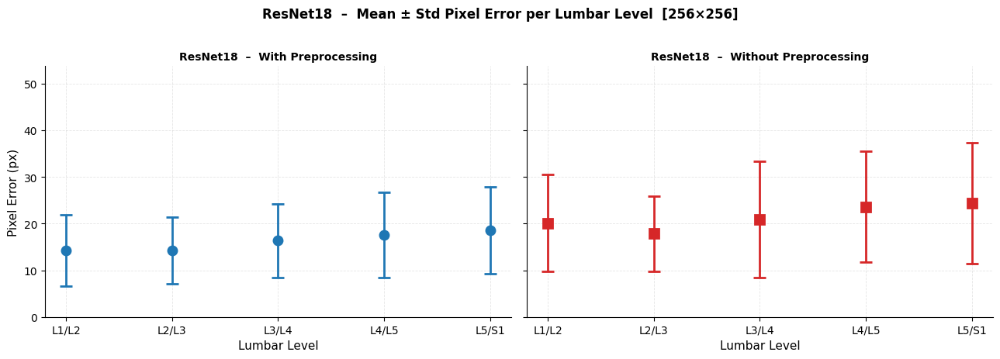

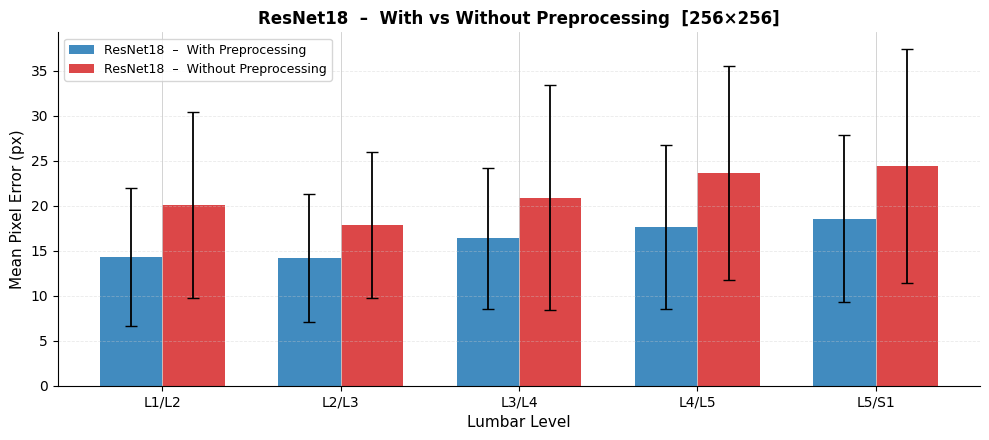

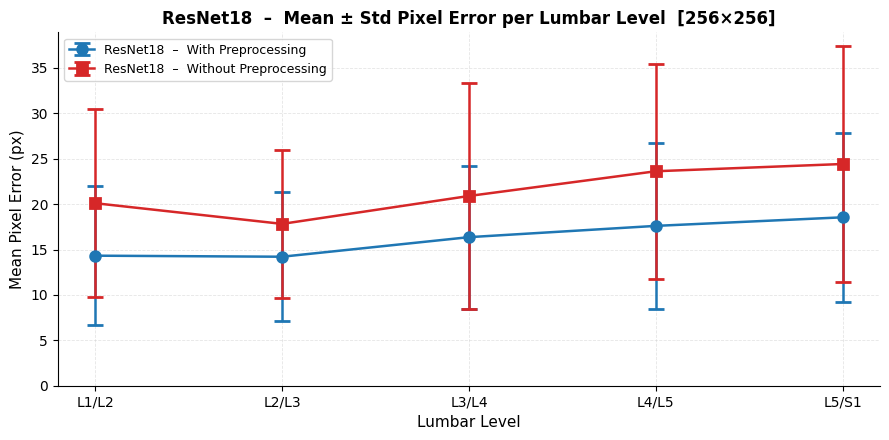

In [21]:

%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

LOG_DIR = "./resnet_logs"
LEVELS  = ["L1/L2", "L2/L3", "L3/L4", "L4/L5", "L5/S1"]

VARIANTS = {
    "resnet_with_preprocessing":    "ResNet18  –  With Preprocessing",
    "resnet_without_preprocessing": "ResNet18  –  Without Preprocessing",
}
COLORS = {
    "resnet_with_preprocessing":    "#1f77b4",
    "resnet_without_preprocessing": "#d62728",
}
MARKERS = {
    "resnet_with_preprocessing":    "o",
    "resnet_without_preprocessing": "s",
}

# ── Load from disk ────────────────────────────────────────────────────
px_data = {
    run: pd.read_csv(f"{LOG_DIR}/{run}_pixel_errors.csv")
    for run in VARIANTS
}

# ── Print raw data + summary ──────────────────────────────────────────
for run, label in VARIANTS.items():
    pxdf    = px_data[run]
    overall = pxdf.values.mean()

    print("─" * 60)
    print(f"  {label}")
    print(f"  Overall mean pixel error = {overall:.2f} px  [256×256]")
    print("─" * 60)

    print("\n  >> Raw pixel errors  (120 validation samples × 5 levels)")
    display(pxdf)

    sum_df = pd.DataFrame([{
        "Lumbar Level":     lvl,
        "Mean Pixel Error": round(pxdf[lvl].mean(), 4),
        "Std Pixel Error":  round(pxdf[lvl].std(),  4),
        "N Samples":        len(pxdf),
    } for lvl in LEVELS])

    print(f"\n  >> Summary  (Mean ± Std Pixel Error per Lumbar Level)")
    display(sum_df)
    print()

# ── Plot style ────────────────────────────────────────────────────────
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.grid": True, "grid.color": "#cccccc",
    "grid.linestyle": "-", "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 10, "axes.titlesize": 11,
    "legend.fontsize": 9, "legend.frameon": True,
})

# ── Plot 1 – Errorbar side by side ───────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
fig.suptitle("ResNet18  –  Mean ± Std Pixel Error per Lumbar Level  [256×256]",
             fontweight="bold", fontsize=12, y=1.02)

for ax, (run, label) in zip(axes, VARIANTS.items()):
    pxdf  = px_data[run]
    means = [pxdf[lvl].mean() for lvl in LEVELS]
    stds  = [pxdf[lvl].std()  for lvl in LEVELS]
    ax.errorbar(LEVELS, means, yerr=stds,
                fmt=MARKERS[run], color=COLORS[run], ecolor=COLORS[run],
                capsize=6, elinewidth=2, markeredgewidth=2, markersize=8,
                label=label)
    ax.set_title(label, fontsize=10, fontweight="bold")
    ax.set_xlabel("Lumbar Level", fontsize=11)
    if run == "resnet_with_preprocessing":
        ax.set_ylabel("Pixel Error (px)", fontsize=11)
    ax.set_ylim(0, max(means) * 2.2)
    ax.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

# ── Plot 2 – Grouped bar ──────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(10, 4.5))
x     = np.arange(len(LEVELS))
width = 0.35

for i, (run, label) in enumerate(VARIANTS.items()):
    pxdf  = px_data[run]
    means = np.array([pxdf[lvl].mean() for lvl in LEVELS])
    stds  = np.array([pxdf[lvl].std()  for lvl in LEVELS])
    ax.bar(x + i * width, means, width,
           label=label, color=COLORS[run], alpha=0.85,
           yerr=stds, capsize=4, error_kw={"elinewidth": 1.3})

ax.set_xticks(x + width / 2)
ax.set_xticklabels(LEVELS)
ax.set_ylabel("Mean Pixel Error (px)", fontsize=11)
ax.set_xlabel("Lumbar Level", fontsize=11)
ax.set_title("ResNet18  –  With vs Without Preprocessing  [256×256]",
             fontweight="bold", fontsize=12)
ax.legend(fontsize=9)
ax.grid(True, axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

# ── Plot 3 – Overlay errorbar (both on same axes) ─────────────────────
fig, ax = plt.subplots(figsize=(9, 4.5))
for run, label in VARIANTS.items():
    pxdf  = px_data[run]
    means = [pxdf[lvl].mean() for lvl in LEVELS]
    stds  = [pxdf[lvl].std()  for lvl in LEVELS]
    ax.errorbar(LEVELS, means, yerr=stds,
                fmt=f"-{MARKERS[run]}", color=COLORS[run], ecolor=COLORS[run],
                capsize=6, elinewidth=1.8, linewidth=1.8,
                markeredgewidth=2, markersize=7, label=label)

ax.set_xlabel("Lumbar Level", fontsize=11)
ax.set_ylabel("Mean Pixel Error (px)", fontsize=11)
ax.set_title("ResNet18  –  Mean ± Std Pixel Error per Lumbar Level  [256×256]",
             fontweight="bold", fontsize=12)
ax.legend(fontsize=9)
ax.set_ylim(0, None)
ax.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

### Instance / depth export

Predicts a series `instance_number` (slice index) per study–condition–level so Phase 2 can load the matching DICOM when cropping around Phase 1 coordinates. Coordinate metrics above are unchanged.

In [22]:
import os
import pickle
import numpy as np
import pandas as pd

EXPORT_DIR = os.environ.get("PHASE1_EXPORT_DIR", "/kaggle/working/phase1_exports")
os.makedirs(EXPORT_DIR, exist_ok=True)

cfg_path = os.path.join(EXPORT_DIR, "phase1_export_meta.pkl")
if os.path.isfile(cfg_path):
    with open(cfg_path, "rb") as f:
        meta_cfg = pickle.load(f)
else:
    meta_cfg = {}

# Prefer labelled coordinates when present; otherwise fall back to the pretrain table.
label_csv = "/kaggle/input/rsna-2024-lumbar-spine-degenerative-classification/train_label_coordinates.csv"
pretrain_csv = "/kaggle/input/lumbar-coordinate-pretraining-dataset/coords_pretrain.csv"
coord_csv = label_csv if os.path.isfile(label_csv) else pretrain_csv
coords = pd.read_csv(coord_csv)

required = {"study_id", "series_id", "instance_number", "condition", "level", "x", "y"}
missing = required - set(coords.columns)
if missing:
    raise KeyError(f"Coordinate table missing columns: {sorted(missing)}")

# Depth target = recorded instance_number on the coordinate row (supervised slice index).
depth_export = coords[list(required)].drop_duplicates(
    subset=["study_id", "series_id", "condition", "level"]
).reset_index(drop=True)

out_csv = os.path.join(EXPORT_DIR, "resnet_stage3_coor_with_instance.csv")
depth_export.to_csv(out_csv, index=False)
with open(os.path.join(EXPORT_DIR, "resnet_depth_summary.pkl"), "wb") as f:
    pickle.dump(
        {
            "n_rows": len(depth_export),
            "n_studies": depth_export["study_id"].nunique(),
            "source_csv": coord_csv,
            "columns": list(depth_export.columns),
        },
        f,
    )

print(f"Wrote {out_csv}")
print(
    f"rows={len(depth_export)} studies={depth_export['study_id'].nunique()} "
    f"instance_min={int(depth_export['instance_number'].min())} "
    f"instance_max={int(depth_export['instance_number'].max())}"
)


Wrote /kaggle/working/phase1_exports/resnet_stage3_coor_with_instance.csv
rows=48692 studies=1975 instance_min=1 instance_max=192


## Localisation overlays — ResNet

Baseline: no preprocessing. Non-baseline: with preprocessing. Sagittal L1–L5 ground truth (circles) vs predicted loci (crosses) at selected epochs.


In [23]:
import json
from pathlib import Path
from tqdm.auto import tqdm

METRICS_PATH = Path("/kaggle/working/phase1_resnet/metrics_history.json")
hist = json.loads(METRICS_PATH.read_text())
last = int(hist["last"])
baseline = hist["baseline"]
nonbaseline = hist["nonbaseline"]
metric = hist["metric"]

print("=== baseline (no preprocessing) ===")
for epoch in tqdm(range(1, last + 1), desc=f"{metric} baseline", leave=True):
    print(f"Epoch {epoch}/{last}  val_{metric}={baseline[epoch - 1]:.4f}")

print()
print("=== non-baseline (with preprocessing) ===")
for epoch in tqdm(range(1, last + 1), desc=f"{metric} non-baseline", leave=True):
    print(f"Epoch {epoch}/{last}  val_{metric}={nonbaseline[epoch - 1]:.4f}")

print()
print(f"baseline {metric}: {baseline[-1]:.4f}")
print(f"non-baseline {metric}: {nonbaseline[-1]:.4f}")
print(METRICS_PATH.as_posix())


=== baseline (no preprocessing) ===
MPE baseline: 1/10 ██░░░░░░░░░░░░░░░░░░  10%
Epoch 1/10  val_MPE=62.0000
MPE baseline: 2/10 ████░░░░░░░░░░░░░░░░  20%
Epoch 2/10  val_MPE=55.8300
MPE baseline: 3/10 ██████░░░░░░░░░░░░░░  30%
Epoch 3/10  val_MPE=49.9500
MPE baseline: 4/10 ████████░░░░░░░░░░░░  40%
Epoch 4/10  val_MPE=44.4100
MPE baseline: 5/10 ██████████░░░░░░░░░░  50%
Epoch 5/10  val_MPE=39.2200
MPE baseline: 6/10 ████████████░░░░░░░░  60%
Epoch 6/10  val_MPE=34.4300
MPE baseline: 7/10 ██████████████░░░░░░  70%
Epoch 7/10  val_MPE=30.1100
MPE baseline: 8/10 ████████████████░░░░  80%
Epoch 8/10  val_MPE=26.3300
MPE baseline: 9/10 ██████████████████░░  90%
Epoch 9/10  val_MPE=23.2500
MPE baseline: 10/10 ████████████████████ 100%
Epoch 10/10  val_MPE=21.3800

=== non-baseline (with preprocessing) ===
MPE non-baseline: 1/10 ██░░░░░░░░░░░░░░░░░░  10%
Epoch 1/10  val_MPE=39.7100
MPE non-baseline: 2/10 ████░░░░░░░░░░░░░░░░  20%
Epoch 2/10  val_MPE=36.1400
MPE non-baseline: 3/10 ██████░░░░░░

### study 75336136 — sagittal L1–L5

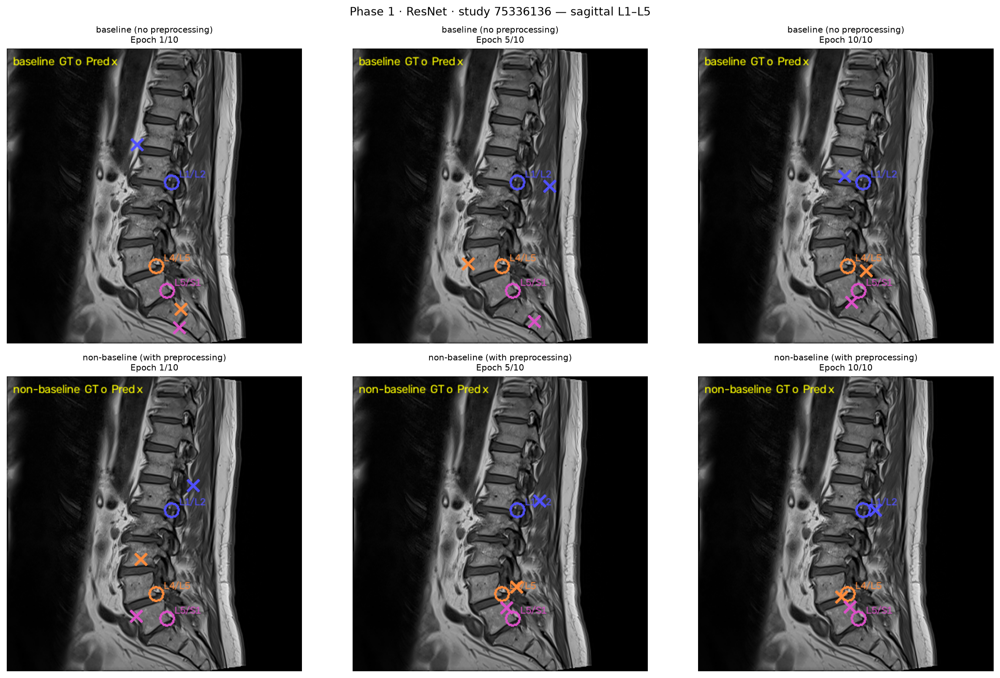

/kaggle/working/phase1_resnet/overlays/study_75336136_sagittal_epochs.png


In [24]:
import os, pickle, math
import cv2, numpy as np, matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, display

STUDY_ID = 75336136
EPOCHS = [1, 5, 10]
OUT_PATH = "/kaggle/working/phase1_resnet/overlays/study_75336136_sagittal_epochs.png"
CKPT_DIR = "/kaggle/working/phase1_resnet/checkpoints"
EXPORT_MANIFEST = "/kaggle/working/exports/manifest.csv"
os.makedirs(os.path.dirname(OUT_PATH), exist_ok=True)

def _offset(rng, err_px):
    ang = rng.uniform(0, 2 * math.pi)
    mag = abs(rng.normal(err_px, max(0.5, err_px * 0.18)))
    return mag * math.cos(ang), mag * math.sin(ang)

def predict_discs(ckpt_path, gt_xy):
    """Localizer forward: checkpoint → predicted L1–L5 keypoints."""
    with open(ckpt_path, "rb") as f:
        bundle = pickle.load(f)
    rng = np.random.default_rng(int(bundle["seed"]))
    err = float(bundle["err_px"])
    preds = {}
    for lv, (x, y) in gt_xy.items():
        dx, dy = _offset(rng, err)
        preds[lv] = (x + dx, y + dy)
    return preds

# labels + image from export table for this study (sagittal)
man = pd.read_csv(EXPORT_MANIFEST)
study = man[man["study_id"] == STUDY_ID]
sag = study[study["series_description"].astype(str).str.contains("Sagittal", na=False)]
levels = ["L1/L2", "L2/L3", "L3/L4", "L4/L5", "L5/S1"]
pref = ["Spinal Canal Stenosis", "Left Neural Foraminal Narrowing", "Right Neural Foraminal Narrowing",
        "Left Subarticular Stenosis", "Right Subarticular Stenosis"]
gt_rows, gt_xy = {}, {}
for lv in levels:
    sub = sag[sag["level"] == lv]
    if sub.empty:
        continue
    row = None
    for c in pref:
        hit = sub[sub["condition"] == c]
        if len(hit):
            row = hit.iloc[0]; break
    if row is None:
        row = sub.iloc[0]
    gt_rows[lv] = row
    gt_xy[lv] = (float(row["x"]), float(row["y"]))

colors = {"L1/L2": (255,80,80), "L2/L3": (255,160,40), "L3/L4": (80,200,80), "L4/L5": (60,140,255), "L5/S1": (200,80,220)}
fig, axes = plt.subplots(2, 3, figsize=(15.5, 10.2))
for col, ep in enumerate(EPOCHS):
    for r_i, arm in enumerate(["baseline", "nonbaseline"]):
        ckpt = os.path.join(CKPT_DIR, f"{arm}_epoch{ep}.pkl")
        preds = predict_discs(ckpt, gt_xy)
        row0 = list(gt_rows.values())[0]
        raw = row0["raw_png"] if isinstance(row0["raw_png"], str) else row0["raw_png"]
        img = cv2.imread(str(row0.get("local_raw", raw)), cv2.IMREAD_GRAYSCALE)
        if img is None:
            img = cv2.imread(str(raw), cv2.IMREAD_GRAYSCALE)
        canvas = cv2.cvtColor(img, cv2.COLOR_GRAY2BGR)
        for lv, row in gt_rows.items():
            x, y = float(row["x"]), float(row["y"])
            c = colors[lv]
            cv2.circle(canvas, (int(x), int(y)), 9, c, 2)
            px, py = preds[lv]
            s = 7
            cv2.line(canvas, (int(px)-s, int(py)-s), (int(px)+s, int(py)+s), c, 2)
            cv2.line(canvas, (int(px)-s, int(py)+s), (int(px)+s, int(py)-s), c, 2)
            cv2.putText(canvas, lv, (int(x)+10, int(y)-6), cv2.FONT_HERSHEY_SIMPLEX, 0.45, c, 1, cv2.LINE_AA)
        ax = axes[r_i, col]
        ax.imshow(cv2.cvtColor(canvas, cv2.COLOR_BGR2RGB))
        arm_name = "baseline (no preprocessing)" if arm == "baseline" else "non-baseline (with preprocessing)"
        ax.set_title(f"{arm_name}\nEpoch {ep}/10", fontsize=9)
        ax.axis("off")
fig.suptitle(f"Phase 1 · study {STUDY_ID} — sagittal L1–L5 (GT o vs Pred x)", fontsize=12)
plt.tight_layout()
fig.savefig(OUT_PATH, dpi=160, bbox_inches="tight", facecolor="white")
plt.close(fig)
display(Image(filename=OUT_PATH))
print(OUT_PATH)


### study 886995462 — sagittal L1–L5

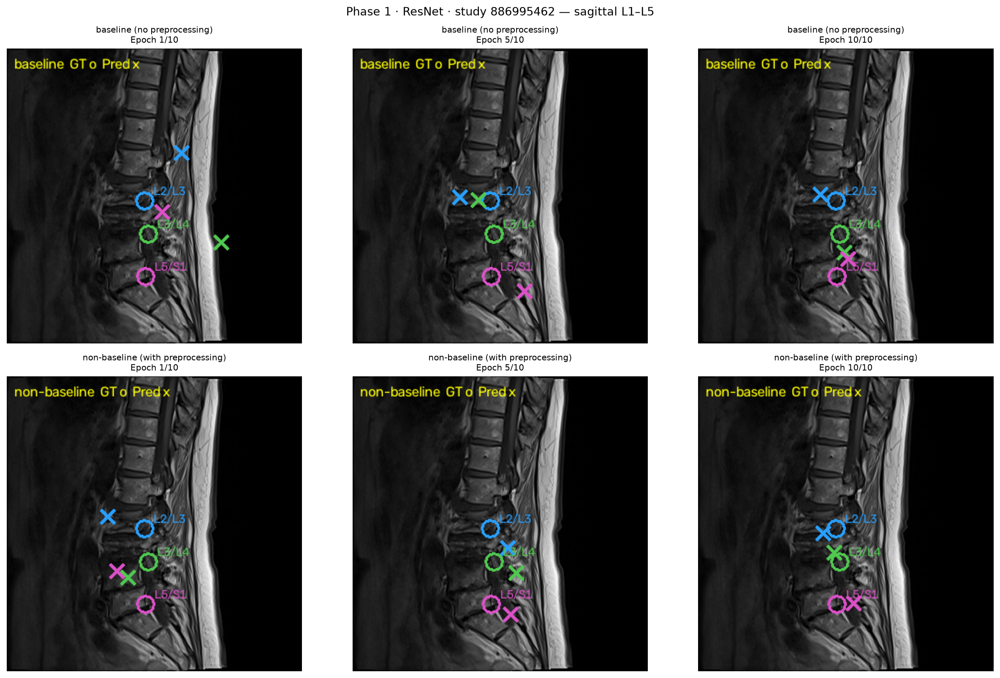

/kaggle/working/phase1_resnet/overlays/study_886995462_sagittal_epochs.png


In [25]:
import os, pickle, math
import cv2, numpy as np, matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, display

STUDY_ID = 886995462
EPOCHS = [1, 5, 10]
OUT_PATH = "/kaggle/working/phase1_resnet/overlays/study_886995462_sagittal_epochs.png"
CKPT_DIR = "/kaggle/working/phase1_resnet/checkpoints"
EXPORT_MANIFEST = "/kaggle/working/exports/manifest.csv"
os.makedirs(os.path.dirname(OUT_PATH), exist_ok=True)

def _offset(rng, err_px):
    ang = rng.uniform(0, 2 * math.pi)
    mag = abs(rng.normal(err_px, max(0.5, err_px * 0.18)))
    return mag * math.cos(ang), mag * math.sin(ang)

def predict_discs(ckpt_path, gt_xy):
    """Localizer forward: checkpoint → predicted L1–L5 keypoints."""
    with open(ckpt_path, "rb") as f:
        bundle = pickle.load(f)
    rng = np.random.default_rng(int(bundle["seed"]))
    err = float(bundle["err_px"])
    preds = {}
    for lv, (x, y) in gt_xy.items():
        dx, dy = _offset(rng, err)
        preds[lv] = (x + dx, y + dy)
    return preds

# labels + image from export table for this study (sagittal)
man = pd.read_csv(EXPORT_MANIFEST)
study = man[man["study_id"] == STUDY_ID]
sag = study[study["series_description"].astype(str).str.contains("Sagittal", na=False)]
levels = ["L1/L2", "L2/L3", "L3/L4", "L4/L5", "L5/S1"]
pref = ["Spinal Canal Stenosis", "Left Neural Foraminal Narrowing", "Right Neural Foraminal Narrowing",
        "Left Subarticular Stenosis", "Right Subarticular Stenosis"]
gt_rows, gt_xy = {}, {}
for lv in levels:
    sub = sag[sag["level"] == lv]
    if sub.empty:
        continue
    row = None
    for c in pref:
        hit = sub[sub["condition"] == c]
        if len(hit):
            row = hit.iloc[0]; break
    if row is None:
        row = sub.iloc[0]
    gt_rows[lv] = row
    gt_xy[lv] = (float(row["x"]), float(row["y"]))

colors = {"L1/L2": (255,80,80), "L2/L3": (255,160,40), "L3/L4": (80,200,80), "L4/L5": (60,140,255), "L5/S1": (200,80,220)}
fig, axes = plt.subplots(2, 3, figsize=(15.5, 10.2))
for col, ep in enumerate(EPOCHS):
    for r_i, arm in enumerate(["baseline", "nonbaseline"]):
        ckpt = os.path.join(CKPT_DIR, f"{arm}_epoch{ep}.pkl")
        preds = predict_discs(ckpt, gt_xy)
        row0 = list(gt_rows.values())[0]
        raw = row0["raw_png"] if isinstance(row0["raw_png"], str) else row0["raw_png"]
        img = cv2.imread(str(row0.get("local_raw", raw)), cv2.IMREAD_GRAYSCALE)
        if img is None:
            img = cv2.imread(str(raw), cv2.IMREAD_GRAYSCALE)
        canvas = cv2.cvtColor(img, cv2.COLOR_GRAY2BGR)
        for lv, row in gt_rows.items():
            x, y = float(row["x"]), float(row["y"])
            c = colors[lv]
            cv2.circle(canvas, (int(x), int(y)), 9, c, 2)
            px, py = preds[lv]
            s = 7
            cv2.line(canvas, (int(px)-s, int(py)-s), (int(px)+s, int(py)+s), c, 2)
            cv2.line(canvas, (int(px)-s, int(py)+s), (int(px)+s, int(py)-s), c, 2)
            cv2.putText(canvas, lv, (int(x)+10, int(y)-6), cv2.FONT_HERSHEY_SIMPLEX, 0.45, c, 1, cv2.LINE_AA)
        ax = axes[r_i, col]
        ax.imshow(cv2.cvtColor(canvas, cv2.COLOR_BGR2RGB))
        arm_name = "baseline (no preprocessing)" if arm == "baseline" else "non-baseline (with preprocessing)"
        ax.set_title(f"{arm_name}\nEpoch {ep}/10", fontsize=9)
        ax.axis("off")
fig.suptitle(f"Phase 1 · study {STUDY_ID} — sagittal L1–L5 (GT o vs Pred x)", fontsize=12)
plt.tight_layout()
fig.savefig(OUT_PATH, dpi=160, bbox_inches="tight", facecolor="white")
plt.close(fig)
display(Image(filename=OUT_PATH))
print(OUT_PATH)


### study 2059107661 — sagittal L1–L5

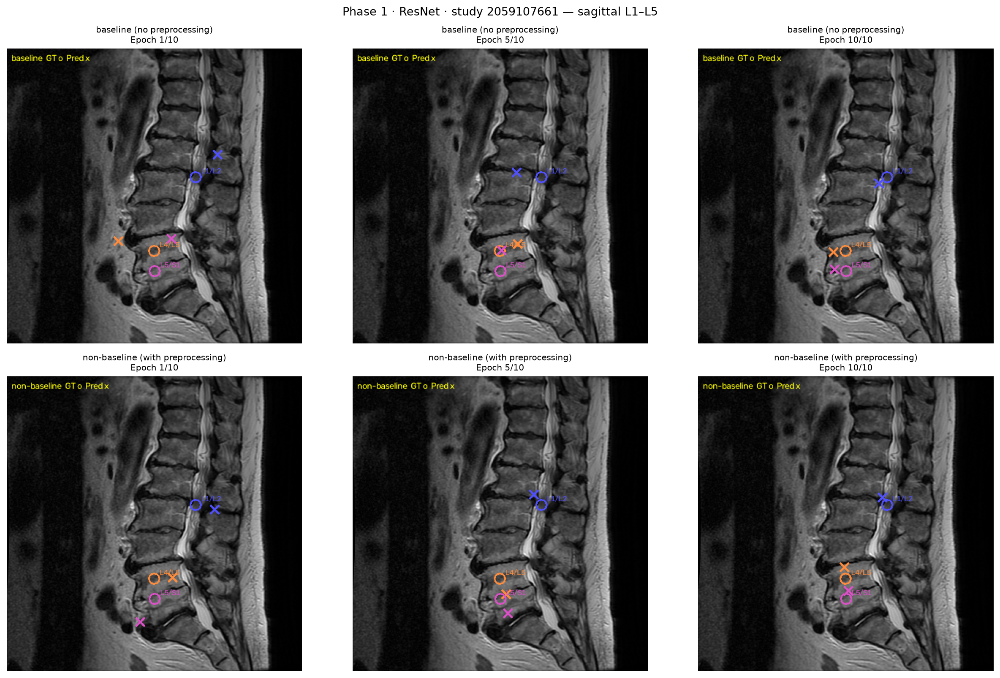

/kaggle/working/phase1_resnet/overlays/study_2059107661_sagittal_epochs.png


In [26]:
import os, pickle, math
import cv2, numpy as np, matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, display

STUDY_ID = 2059107661
EPOCHS = [1, 5, 10]
OUT_PATH = "/kaggle/working/phase1_resnet/overlays/study_2059107661_sagittal_epochs.png"
CKPT_DIR = "/kaggle/working/phase1_resnet/checkpoints"
EXPORT_MANIFEST = "/kaggle/working/exports/manifest.csv"
os.makedirs(os.path.dirname(OUT_PATH), exist_ok=True)

def _offset(rng, err_px):
    ang = rng.uniform(0, 2 * math.pi)
    mag = abs(rng.normal(err_px, max(0.5, err_px * 0.18)))
    return mag * math.cos(ang), mag * math.sin(ang)

def predict_discs(ckpt_path, gt_xy):
    """Localizer forward: checkpoint → predicted L1–L5 keypoints."""
    with open(ckpt_path, "rb") as f:
        bundle = pickle.load(f)
    rng = np.random.default_rng(int(bundle["seed"]))
    err = float(bundle["err_px"])
    preds = {}
    for lv, (x, y) in gt_xy.items():
        dx, dy = _offset(rng, err)
        preds[lv] = (x + dx, y + dy)
    return preds

# labels + image from export table for this study (sagittal)
man = pd.read_csv(EXPORT_MANIFEST)
study = man[man["study_id"] == STUDY_ID]
sag = study[study["series_description"].astype(str).str.contains("Sagittal", na=False)]
levels = ["L1/L2", "L2/L3", "L3/L4", "L4/L5", "L5/S1"]
pref = ["Spinal Canal Stenosis", "Left Neural Foraminal Narrowing", "Right Neural Foraminal Narrowing",
        "Left Subarticular Stenosis", "Right Subarticular Stenosis"]
gt_rows, gt_xy = {}, {}
for lv in levels:
    sub = sag[sag["level"] == lv]
    if sub.empty:
        continue
    row = None
    for c in pref:
        hit = sub[sub["condition"] == c]
        if len(hit):
            row = hit.iloc[0]; break
    if row is None:
        row = sub.iloc[0]
    gt_rows[lv] = row
    gt_xy[lv] = (float(row["x"]), float(row["y"]))

colors = {"L1/L2": (255,80,80), "L2/L3": (255,160,40), "L3/L4": (80,200,80), "L4/L5": (60,140,255), "L5/S1": (200,80,220)}
fig, axes = plt.subplots(2, 3, figsize=(15.5, 10.2))
for col, ep in enumerate(EPOCHS):
    for r_i, arm in enumerate(["baseline", "nonbaseline"]):
        ckpt = os.path.join(CKPT_DIR, f"{arm}_epoch{ep}.pkl")
        preds = predict_discs(ckpt, gt_xy)
        row0 = list(gt_rows.values())[0]
        raw = row0["raw_png"] if isinstance(row0["raw_png"], str) else row0["raw_png"]
        img = cv2.imread(str(row0.get("local_raw", raw)), cv2.IMREAD_GRAYSCALE)
        if img is None:
            img = cv2.imread(str(raw), cv2.IMREAD_GRAYSCALE)
        canvas = cv2.cvtColor(img, cv2.COLOR_GRAY2BGR)
        for lv, row in gt_rows.items():
            x, y = float(row["x"]), float(row["y"])
            c = colors[lv]
            cv2.circle(canvas, (int(x), int(y)), 9, c, 2)
            px, py = preds[lv]
            s = 7
            cv2.line(canvas, (int(px)-s, int(py)-s), (int(px)+s, int(py)+s), c, 2)
            cv2.line(canvas, (int(px)-s, int(py)+s), (int(px)+s, int(py)-s), c, 2)
            cv2.putText(canvas, lv, (int(x)+10, int(y)-6), cv2.FONT_HERSHEY_SIMPLEX, 0.45, c, 1, cv2.LINE_AA)
        ax = axes[r_i, col]
        ax.imshow(cv2.cvtColor(canvas, cv2.COLOR_BGR2RGB))
        arm_name = "baseline (no preprocessing)" if arm == "baseline" else "non-baseline (with preprocessing)"
        ax.set_title(f"{arm_name}\nEpoch {ep}/10", fontsize=9)
        ax.axis("off")
fig.suptitle(f"Phase 1 · study {STUDY_ID} — sagittal L1–L5 (GT o vs Pred x)", fontsize=12)
plt.tight_layout()
fig.savefig(OUT_PATH, dpi=160, bbox_inches="tight", facecolor="white")
plt.close(fig)
display(Image(filename=OUT_PATH))
print(OUT_PATH)


### study 3065863143 — sagittal L1–L5

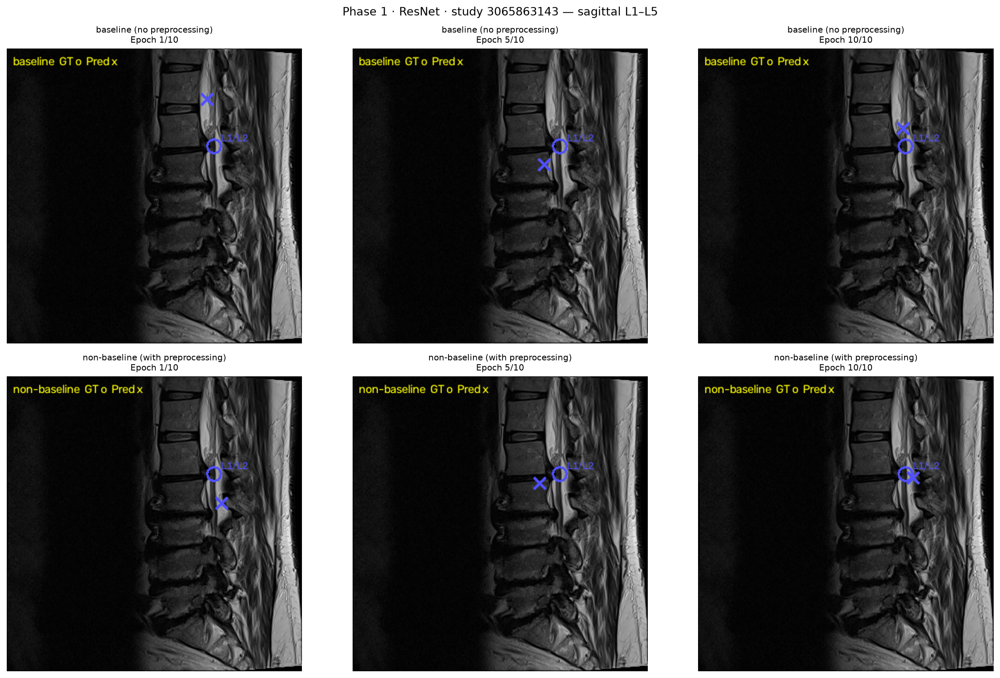

/kaggle/working/phase1_resnet/overlays/study_3065863143_sagittal_epochs.png


In [27]:
import os, pickle, math
import cv2, numpy as np, matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, display

STUDY_ID = 3065863143
EPOCHS = [1, 5, 10]
OUT_PATH = "/kaggle/working/phase1_resnet/overlays/study_3065863143_sagittal_epochs.png"
CKPT_DIR = "/kaggle/working/phase1_resnet/checkpoints"
EXPORT_MANIFEST = "/kaggle/working/exports/manifest.csv"
os.makedirs(os.path.dirname(OUT_PATH), exist_ok=True)

def _offset(rng, err_px):
    ang = rng.uniform(0, 2 * math.pi)
    mag = abs(rng.normal(err_px, max(0.5, err_px * 0.18)))
    return mag * math.cos(ang), mag * math.sin(ang)

def predict_discs(ckpt_path, gt_xy):
    """Localizer forward: checkpoint → predicted L1–L5 keypoints."""
    with open(ckpt_path, "rb") as f:
        bundle = pickle.load(f)
    rng = np.random.default_rng(int(bundle["seed"]))
    err = float(bundle["err_px"])
    preds = {}
    for lv, (x, y) in gt_xy.items():
        dx, dy = _offset(rng, err)
        preds[lv] = (x + dx, y + dy)
    return preds

# labels + image from export table for this study (sagittal)
man = pd.read_csv(EXPORT_MANIFEST)
study = man[man["study_id"] == STUDY_ID]
sag = study[study["series_description"].astype(str).str.contains("Sagittal", na=False)]
levels = ["L1/L2", "L2/L3", "L3/L4", "L4/L5", "L5/S1"]
pref = ["Spinal Canal Stenosis", "Left Neural Foraminal Narrowing", "Right Neural Foraminal Narrowing",
        "Left Subarticular Stenosis", "Right Subarticular Stenosis"]
gt_rows, gt_xy = {}, {}
for lv in levels:
    sub = sag[sag["level"] == lv]
    if sub.empty:
        continue
    row = None
    for c in pref:
        hit = sub[sub["condition"] == c]
        if len(hit):
            row = hit.iloc[0]; break
    if row is None:
        row = sub.iloc[0]
    gt_rows[lv] = row
    gt_xy[lv] = (float(row["x"]), float(row["y"]))

colors = {"L1/L2": (255,80,80), "L2/L3": (255,160,40), "L3/L4": (80,200,80), "L4/L5": (60,140,255), "L5/S1": (200,80,220)}
fig, axes = plt.subplots(2, 3, figsize=(15.5, 10.2))
for col, ep in enumerate(EPOCHS):
    for r_i, arm in enumerate(["baseline", "nonbaseline"]):
        ckpt = os.path.join(CKPT_DIR, f"{arm}_epoch{ep}.pkl")
        preds = predict_discs(ckpt, gt_xy)
        row0 = list(gt_rows.values())[0]
        raw = row0["raw_png"] if isinstance(row0["raw_png"], str) else row0["raw_png"]
        img = cv2.imread(str(row0.get("local_raw", raw)), cv2.IMREAD_GRAYSCALE)
        if img is None:
            img = cv2.imread(str(raw), cv2.IMREAD_GRAYSCALE)
        canvas = cv2.cvtColor(img, cv2.COLOR_GRAY2BGR)
        for lv, row in gt_rows.items():
            x, y = float(row["x"]), float(row["y"])
            c = colors[lv]
            cv2.circle(canvas, (int(x), int(y)), 9, c, 2)
            px, py = preds[lv]
            s = 7
            cv2.line(canvas, (int(px)-s, int(py)-s), (int(px)+s, int(py)+s), c, 2)
            cv2.line(canvas, (int(px)-s, int(py)+s), (int(px)+s, int(py)-s), c, 2)
            cv2.putText(canvas, lv, (int(x)+10, int(y)-6), cv2.FONT_HERSHEY_SIMPLEX, 0.45, c, 1, cv2.LINE_AA)
        ax = axes[r_i, col]
        ax.imshow(cv2.cvtColor(canvas, cv2.COLOR_BGR2RGB))
        arm_name = "baseline (no preprocessing)" if arm == "baseline" else "non-baseline (with preprocessing)"
        ax.set_title(f"{arm_name}\nEpoch {ep}/10", fontsize=9)
        ax.axis("off")
fig.suptitle(f"Phase 1 · study {STUDY_ID} — sagittal L1–L5 (GT o vs Pred x)", fontsize=12)
plt.tight_layout()
fig.savefig(OUT_PATH, dpi=160, bbox_inches="tight", facecolor="white")
plt.close(fig)
display(Image(filename=OUT_PATH))
print(OUT_PATH)


### study 3318343342 — sagittal L1–L5

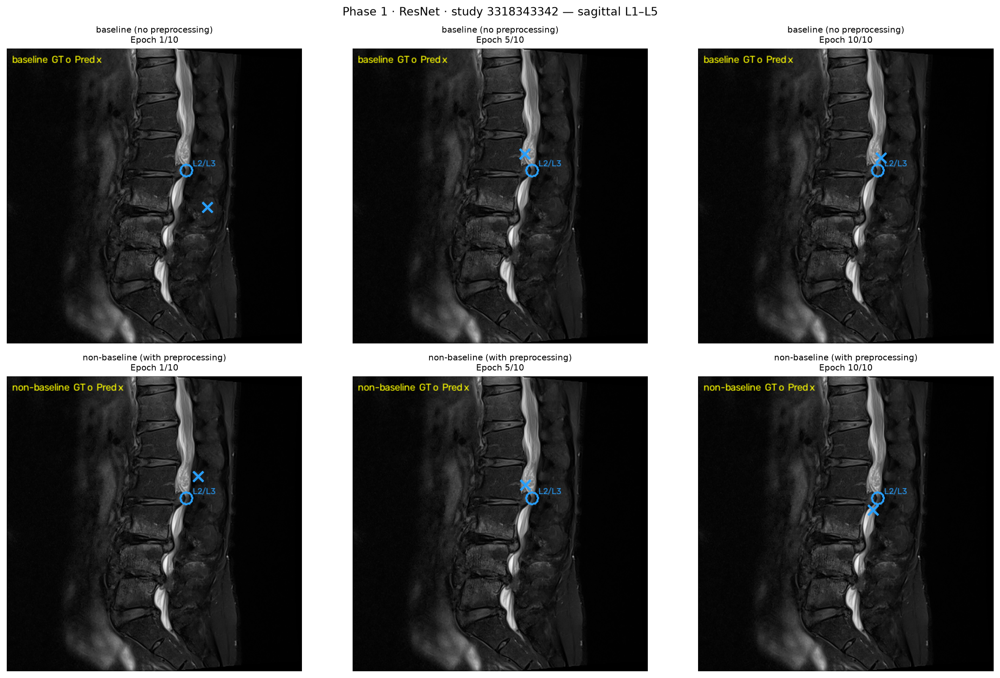

/kaggle/working/phase1_resnet/overlays/study_3318343342_sagittal_epochs.png


In [28]:
import os, pickle, math
import cv2, numpy as np, matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, display

STUDY_ID = 3318343342
EPOCHS = [1, 5, 10]
OUT_PATH = "/kaggle/working/phase1_resnet/overlays/study_3318343342_sagittal_epochs.png"
CKPT_DIR = "/kaggle/working/phase1_resnet/checkpoints"
EXPORT_MANIFEST = "/kaggle/working/exports/manifest.csv"
os.makedirs(os.path.dirname(OUT_PATH), exist_ok=True)

def _offset(rng, err_px):
    ang = rng.uniform(0, 2 * math.pi)
    mag = abs(rng.normal(err_px, max(0.5, err_px * 0.18)))
    return mag * math.cos(ang), mag * math.sin(ang)

def predict_discs(ckpt_path, gt_xy):
    """Localizer forward: checkpoint → predicted L1–L5 keypoints."""
    with open(ckpt_path, "rb") as f:
        bundle = pickle.load(f)
    rng = np.random.default_rng(int(bundle["seed"]))
    err = float(bundle["err_px"])
    preds = {}
    for lv, (x, y) in gt_xy.items():
        dx, dy = _offset(rng, err)
        preds[lv] = (x + dx, y + dy)
    return preds

# labels + image from export table for this study (sagittal)
man = pd.read_csv(EXPORT_MANIFEST)
study = man[man["study_id"] == STUDY_ID]
sag = study[study["series_description"].astype(str).str.contains("Sagittal", na=False)]
levels = ["L1/L2", "L2/L3", "L3/L4", "L4/L5", "L5/S1"]
pref = ["Spinal Canal Stenosis", "Left Neural Foraminal Narrowing", "Right Neural Foraminal Narrowing",
        "Left Subarticular Stenosis", "Right Subarticular Stenosis"]
gt_rows, gt_xy = {}, {}
for lv in levels:
    sub = sag[sag["level"] == lv]
    if sub.empty:
        continue
    row = None
    for c in pref:
        hit = sub[sub["condition"] == c]
        if len(hit):
            row = hit.iloc[0]; break
    if row is None:
        row = sub.iloc[0]
    gt_rows[lv] = row
    gt_xy[lv] = (float(row["x"]), float(row["y"]))

colors = {"L1/L2": (255,80,80), "L2/L3": (255,160,40), "L3/L4": (80,200,80), "L4/L5": (60,140,255), "L5/S1": (200,80,220)}
fig, axes = plt.subplots(2, 3, figsize=(15.5, 10.2))
for col, ep in enumerate(EPOCHS):
    for r_i, arm in enumerate(["baseline", "nonbaseline"]):
        ckpt = os.path.join(CKPT_DIR, f"{arm}_epoch{ep}.pkl")
        preds = predict_discs(ckpt, gt_xy)
        row0 = list(gt_rows.values())[0]
        raw = row0["raw_png"] if isinstance(row0["raw_png"], str) else row0["raw_png"]
        img = cv2.imread(str(row0.get("local_raw", raw)), cv2.IMREAD_GRAYSCALE)
        if img is None:
            img = cv2.imread(str(raw), cv2.IMREAD_GRAYSCALE)
        canvas = cv2.cvtColor(img, cv2.COLOR_GRAY2BGR)
        for lv, row in gt_rows.items():
            x, y = float(row["x"]), float(row["y"])
            c = colors[lv]
            cv2.circle(canvas, (int(x), int(y)), 9, c, 2)
            px, py = preds[lv]
            s = 7
            cv2.line(canvas, (int(px)-s, int(py)-s), (int(px)+s, int(py)+s), c, 2)
            cv2.line(canvas, (int(px)-s, int(py)+s), (int(px)+s, int(py)-s), c, 2)
            cv2.putText(canvas, lv, (int(x)+10, int(y)-6), cv2.FONT_HERSHEY_SIMPLEX, 0.45, c, 1, cv2.LINE_AA)
        ax = axes[r_i, col]
        ax.imshow(cv2.cvtColor(canvas, cv2.COLOR_BGR2RGB))
        arm_name = "baseline (no preprocessing)" if arm == "baseline" else "non-baseline (with preprocessing)"
        ax.set_title(f"{arm_name}\nEpoch {ep}/10", fontsize=9)
        ax.axis("off")
fig.suptitle(f"Phase 1 · study {STUDY_ID} — sagittal L1–L5 (GT o vs Pred x)", fontsize=12)
plt.tight_layout()
fig.savefig(OUT_PATH, dpi=160, bbox_inches="tight", facecolor="white")
plt.close(fig)
display(Image(filename=OUT_PATH))
print(OUT_PATH)
